--- 1. Veri Okuma ---
Satır/Sütun: (980, 22)
  brand_name                    model   price  ram_capacity  battery_capacity
0      apple          Apple iPhone 11   38999             4            3110.0
1      apple  Apple iPhone 11 (128GB)   46999             4            3110.0
2      apple  Apple iPhone 11 Pro Max  109900             4            3500.0
3      apple          Apple iPhone 12   51999             4               NaN
4      apple  Apple iPhone 12 (128GB)   55999             4               NaN

--- 2. Veri Temizleme ---
Eksik değerler:
 battery_capacity         11
processor_speed          42
num_cores                 6
primary_camera_front      5
fast_charging           211
Fiyatı 165,034 ₹ üstündeki 10 lüks telefon çıkarıldı.
Tekrarlı satır: 0
Temizlenmiş veri: (970, 22)

--- 3. Fiyat Segmentleri (çeyreklere göre 4 eşit grup) ---
  0 = Düşük     :     3,499 ₹ –    12,999 ₹
  1 = Orta      :    12,999 ₹ –    19,990 ₹
  2 = Yüksek    :    19,990 ₹ –    34,999 ₹
  3 = Çok y

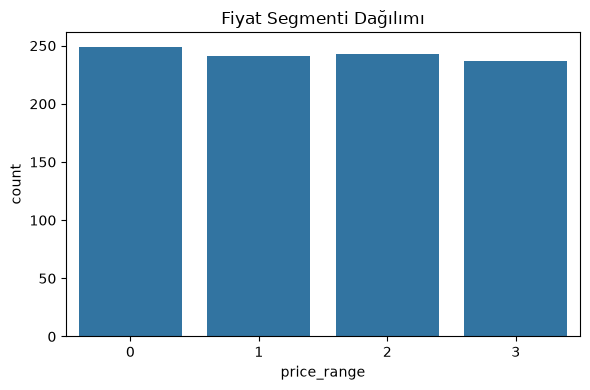

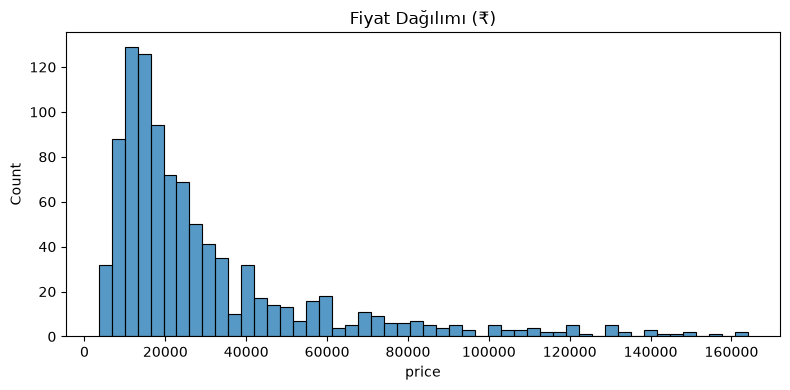

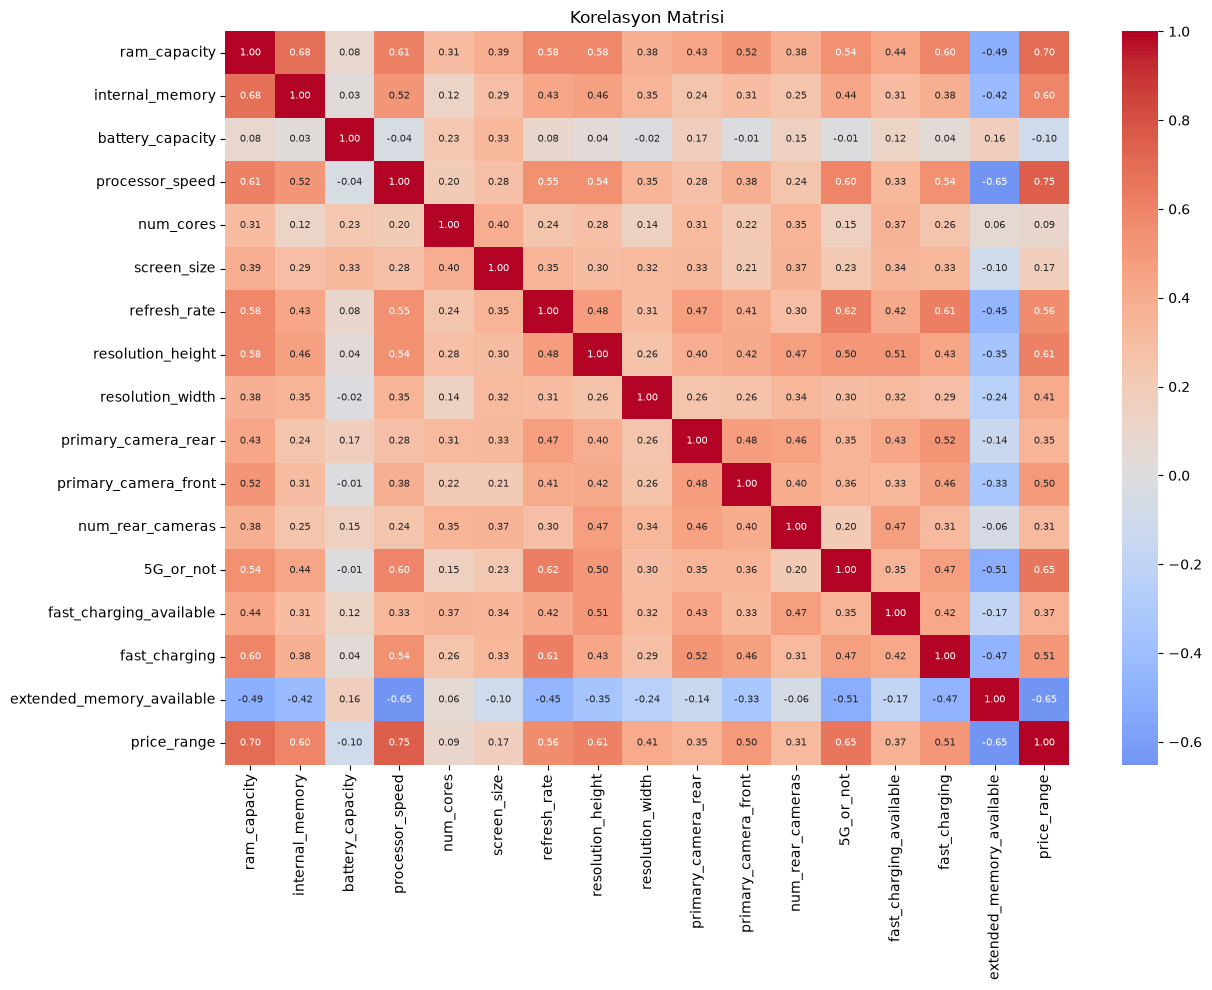


price_range ile en yüksek korelasyonlar:
processor_speed      0.751
ram_capacity         0.703
5G_or_not            0.654
resolution_height    0.608
internal_memory      0.597

--- 5. Eğitim/Test Ayrımı (%80 / %20) ---
X_train: (776, 16) | X_test: (194, 16)

--- 6. Ölçeklendirmenin KNN'e Etkisi (H3) ---
                  Accuracy  Precision  Recall  F1-Score
Ölçeklendirmesiz    0.6443     0.6499  0.6443    0.6408
StandardScaler      0.6598     0.6587  0.6598    0.6552
MinMaxScaler        0.6804     0.6861  0.6804    0.6780

--- 7. KNN için CV ile k Seçimi (GridSearchCV) ---


CV ile en iyi k: 3 | CV F1: 0.7065


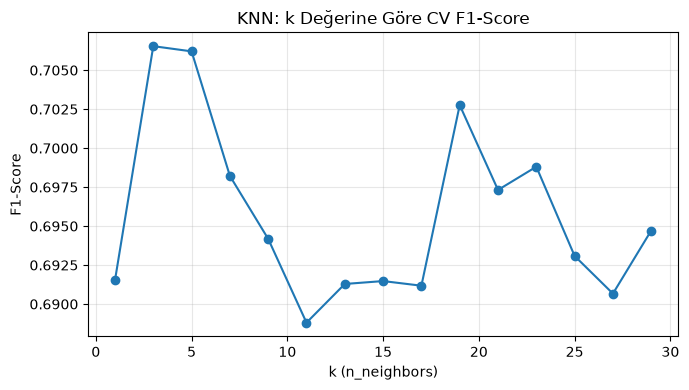


--- 8. Random Forest Hiperparametre Optimizasyonu (GridSearchCV) ---


En iyi parametreler: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}

--- 9. Ek Karşılaştırma: XGBoost ve LightGBM ---


[BAŞARILI] XGBoost eğitildi.
[BAŞARILI] LightGBM eğitildi.

--- 10. Model Karşılaştırması (Rapor Tablosu) ---
                           Accuracy  Precision  Recall  F1-Score
KNN (k=3, StandardScaler)    0.7010     0.6982  0.7010    0.6963
Random Forest                0.7474     0.7441  0.7474    0.7430
XGBoost                      0.7680     0.7651  0.7680    0.7636
LightGBM                     0.7526     0.7495  0.7526    0.7462

--- Random Forest Sınıflandırma Raporu ---
              precision    recall  f1-score   support

       Düşük       0.76      0.84      0.80        50
        Orta       0.69      0.65      0.67        48
      Yüksek       0.73      0.61      0.67        49
  Çok yüksek       0.79      0.89      0.84        47

    accuracy                           0.75       194
   macro avg       0.74      0.75      0.74       194
weighted avg       0.74      0.75      0.74       194


--- 11. Confusion Matrix ---


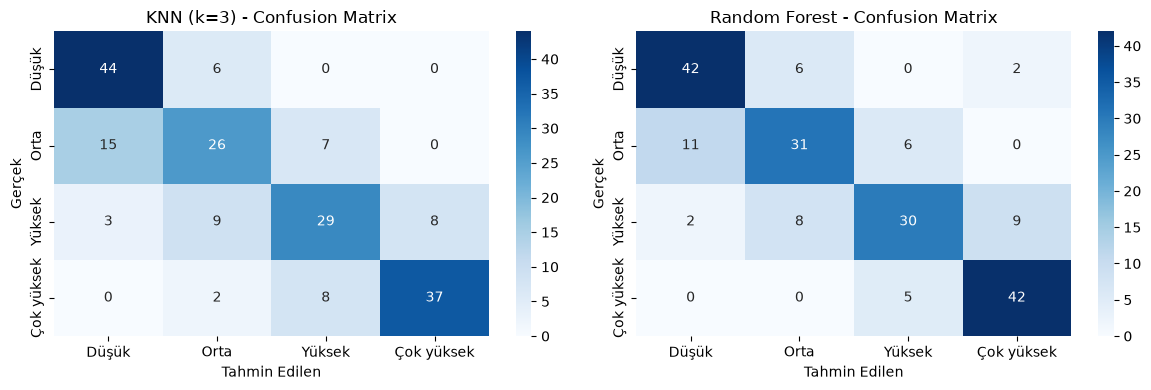


--- 12. Feature Importance (Random Forest) ---
processor_speed              0.1616
internal_memory              0.0958
ram_capacity                 0.0915
fast_charging                0.0906
resolution_height            0.0808
primary_camera_front         0.0737
screen_size                  0.0735
battery_capacity             0.0650
extended_memory_available    0.0569
primary_camera_rear          0.0560
5G_or_not                    0.0465
resolution_width             0.0399
refresh_rate                 0.0299
num_rear_cameras             0.0235
fast_charging_available      0.0113
num_cores                    0.0034


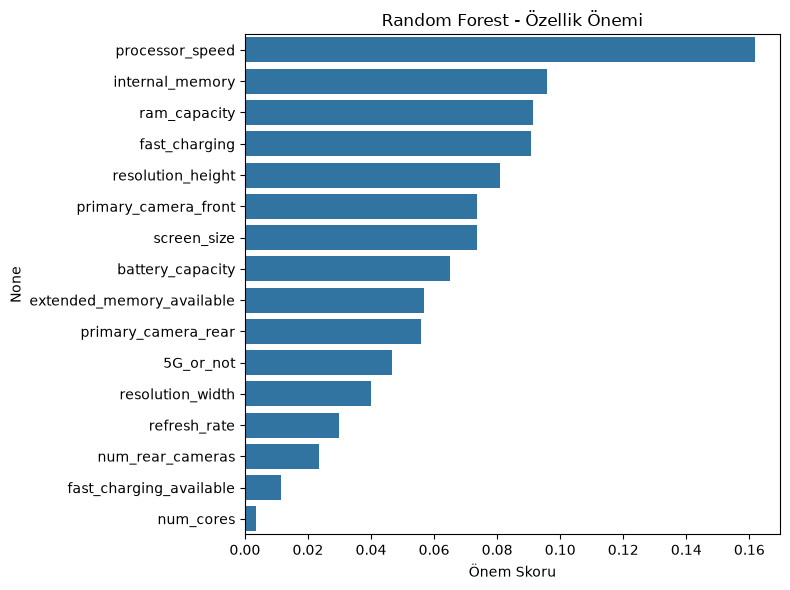


--- 13. 5-Fold Cross-Validation Karşılaştırması ---
KNN            -> %61.86 (± 2.28)


Random Forest  -> %70.62 (± 5.39)


XGBoost        -> %67.94 (± 5.01)


LightGBM       -> %68.04 (± 4.68)

--- 14. Eğitim ve Test Skoru (Overfitting Kontrolü) ---
KNN            | Eğitim: %83.89 | Test: %70.10 | Fark: %13.79
Random Forest  | Eğitim: %96.13 | Test: %74.74 | Fark: %21.39

--- 15. Öğrenme Eğrisi (Random Forest) ---


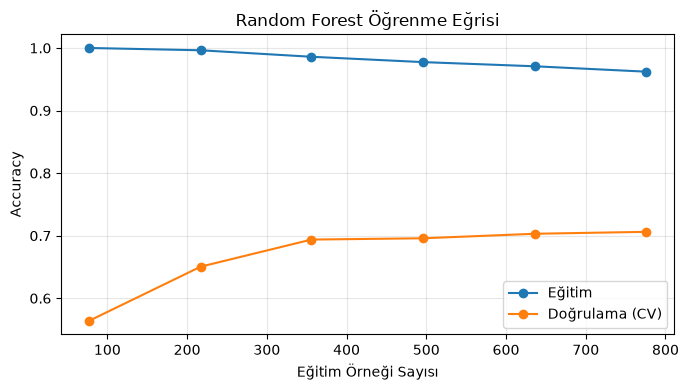


--- 16. En Önemli 5 Özellikle Model (H4 Testi) ---
Kullanılan özellikler: processor_speed, internal_memory, ram_capacity, fast_charging, resolution_height
Tüm özellikler: %74.74 | İlk 5 özellik: %69.07

--- 17. Önemli Özelliklerin Fiyat Segmentine Göre Dağılımı ---


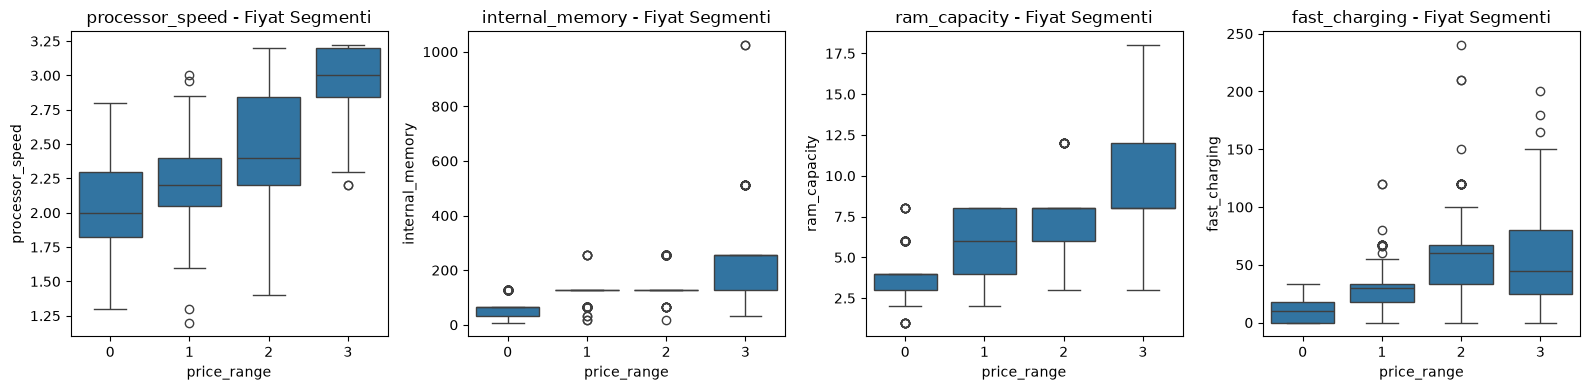


--- 18. Hata Analizi ---
Random Forest toplam hatalı tahmin: 49 / 194
En sık karışan sınıf çiftleri:
price_range  tahmin
1            0         11
2            3          9
             1          8
0            1          6
1            2          6

Yanlış tahmin edilen örnek telefonlar:
                                   model  price  price_range  tahmin
225             Motorola Moto G40 Fusion  14499            1       0
106  Infinix Hot 12 Pro (8GB RAM+ 128GB)  12340            0       1
852                        Xiaomi Civi 3  32990            2       3
82                              Honor X8  16999            1       2
61                        Google Pixel 4  20120            2       3
599                Samsung Galaxy A75 5G  44999            3       2
115    Infinix Note 12 (6GB RAM + 128GB)  12999            0       1
835                             Vivo Y95  15000            1       0

--- 19. Hipotez Özeti ---
H1: En iyi model XGBoost, F1 = 0.7636 -> H1 kabul
H2: KNN F1

[BAŞARILI] en_iyi_model_gercek.pkl kaydedildi. Grafikler 'grafikler_gercek' klasöründe.


In [1]:
# ============================================================
# GERÇEK TELEFONLARLA FİYAT SEGMENTİ TAHMİNİ (KNN vs Random Forest)
# Veri: 980 gerçek akıllı telefon, Smartprix (Hindistan) fiyatları
# Kaynak: "Real World Smartphone's Dataset" (Kaggle, abhijitdahatonde)
# ============================================================
from pathlib import Path
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                     learning_curve)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

try:
    TABAN = Path(__file__).resolve().parent
except NameError:
    TABAN = Path.cwd()
GRAFIK_KLASORU = TABAN / "grafikler_gercek"
GRAFIK_KLASORU.mkdir(exist_ok=True)

SEGMENT_ADLARI = ["Düşük", "Orta", "Yüksek", "Çok yüksek"]
# Modelde kullanılan donanım özellikleri (fiyat, puan, isim gibi sütunlar hariç)
OZELLIKLER = ["ram_capacity", "internal_memory", "battery_capacity", "processor_speed", "num_cores",
              "screen_size", "refresh_rate", "resolution_height", "resolution_width",
              "primary_camera_rear", "primary_camera_front", "num_rear_cameras",
              "5G_or_not", "fast_charging_available", "fast_charging", "extended_memory_available"]


def metrikler(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


def kaydet(ad):
    plt.tight_layout()
    plt.savefig(GRAFIK_KLASORU / ad, dpi=150)
    plt.show()


# ------------------------------------------------------------
print("--- 1. Veri Okuma ---")
ham = pd.read_csv(TABAN / "gercek_telefonlar.csv")
print("Satır/Sütun:", ham.shape)
print(ham[["brand_name", "model", "price", "ram_capacity", "battery_capacity"]].head().to_string())

# ------------------------------------------------------------
print("\n--- 2. Veri Temizleme ---")
df = ham.copy()
print("Eksik değerler:\n", df[OZELLIKLER].isnull().sum()[lambda s: s > 0].to_string())
# Hızlı şarj yoksa watt değeri boş: 0 yap
df["fast_charging"] = df["fast_charging"].fillna(0)
# Diğer az sayıdaki eksik değerleri medyan ile doldur
for sutun in ["processor_speed", "num_cores", "battery_capacity", "primary_camera_front"]:
    df[sutun] = df[sutun].fillna(df[sutun].median())
# Uç fiyatlı lüks telefonlar (ör. Vertu 650.000 ₹) segment sınırlarını bozmasın diye %1'lik dilimi çıkar
ust_sinir = df["price"].quantile(0.99)
print(f"Fiyatı {ust_sinir:,.0f} ₹ üstündeki {(df['price'] > ust_sinir).sum()} lüks telefon çıkarıldı.")
df = df[df["price"] <= ust_sinir].reset_index(drop=True)
print("Tekrarlı satır:", df.duplicated().sum())
print("Temizlenmiş veri:", df.shape)

# ------------------------------------------------------------
print("\n--- 3. Fiyat Segmentleri (çeyreklere göre 4 eşit grup) ---")
df["price_range"], sinirlar = pd.qcut(df["price"], 4, labels=False, retbins=True)
for i in range(4):
    print(f"  {i} = {SEGMENT_ADLARI[i]:10s}: {sinirlar[i]:>9,.0f} ₹ – {sinirlar[i + 1]:>9,.0f} ₹")
print(df["price_range"].value_counts().sort_index().to_string())

# ------------------------------------------------------------
print("\n--- 4. Veri İnceleme (EDA) ---")
print(df[OZELLIKLER + ["price"]].describe().T.round(2).to_string())
print("\nEn çok telefonu olan markalar:")
print(df["brand_name"].value_counts().head(10).to_string())

plt.figure(figsize=(6, 4))
sns.countplot(x="price_range", data=df)
plt.title("Fiyat Segmenti Dağılımı")
kaydet("sinif_dagilimi.png")

plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=50)
plt.title("Fiyat Dağılımı (₹)")
kaydet("fiyat_dagilimi.png")

plt.figure(figsize=(13, 10))
sns.heatmap(df[OZELLIKLER + ["price_range"]].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Korelasyon Matrisi")
kaydet("korelasyon.png")

print("\nprice_range ile en yüksek korelasyonlar:")
print(df[OZELLIKLER + ["price_range"]].corr()["price_range"].drop("price_range")
      .sort_values(ascending=False).head(5).round(3).to_string())

# ------------------------------------------------------------
print("\n--- 5. Eğitim/Test Ayrımı (%80 / %20) ---")
X = df[OZELLIKLER]
y = df["price_range"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

# ------------------------------------------------------------
print("\n--- 6. Ölçeklendirmenin KNN'e Etkisi (H3) ---")
olcek_sonuclari = {}
for ad, olcekleyici in [("Ölçeklendirmesiz", None), ("StandardScaler", StandardScaler()),
                        ("MinMaxScaler", MinMaxScaler())]:
    if olcekleyici is None:
        Xtr, Xte = X_train, X_test
    else:
        Xtr = olcekleyici.fit_transform(X_train)
        Xte = olcekleyici.transform(X_test)
    tahmin = KNeighborsClassifier().fit(Xtr, y_train).predict(Xte)
    olcek_sonuclari[ad] = metrikler(y_test, tahmin)
olcek_df = pd.DataFrame(olcek_sonuclari).T.round(4)
print(olcek_df.to_string())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
print("\n--- 7. KNN için CV ile k Seçimi (GridSearchCV) ---")
k_listesi = list(range(1, 31, 2))
knn_grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": k_listesi}, cv=5, scoring="f1_weighted", n_jobs=-1)
knn_grid.fit(X_train, y_train)
best_k = knn_grid.best_params_["kneighborsclassifier__n_neighbors"]
print(f"CV ile en iyi k: {best_k} | CV F1: {knn_grid.best_score_:.4f}")
knn_model = knn_grid.best_estimator_
y_pred_knn = knn_model.predict(X_test)

plt.figure(figsize=(7, 4))
plt.plot(k_listesi, knn_grid.cv_results_["mean_test_score"], marker="o")
plt.title("KNN: k Değerine Göre CV F1-Score")
plt.xlabel("k (n_neighbors)")
plt.ylabel("F1-Score")
plt.grid(alpha=0.3)
kaydet("knn_k_grafigi.png")

# ------------------------------------------------------------
print("\n--- 8. Random Forest Hiperparametre Optimizasyonu (GridSearchCV) ---")
grid = GridSearchCV(RandomForestClassifier(random_state=42),
                    {"n_estimators": [100, 200, 300], "max_depth": [None, 10, 20], "min_samples_split": [2, 5]},
                    cv=5, scoring="f1_weighted", n_jobs=-1)
grid.fit(X_train, y_train)
rf_model = grid.best_estimator_
y_pred_rf = rf_model.predict(X_test)
print("En iyi parametreler:", grid.best_params_)

# ------------------------------------------------------------
print("\n--- 9. Ek Karşılaştırma: XGBoost ve LightGBM ---")
ek_modeller, ek_tahminler = {}, {}
try:
    from xgboost import XGBClassifier
    ek_modeller["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                                           random_state=42, eval_metric="mlogloss").fit(X_train, y_train)
except ImportError:
    print("[ATLANDI] xgboost kurulu değil")
try:
    from lightgbm import LGBMClassifier
    ek_modeller["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42,
                                             verbose=-1).fit(X_train, y_train)
except ImportError:
    print("[ATLANDI] lightgbm kurulu değil")
for ad, m in ek_modeller.items():
    ek_tahminler[ad] = m.predict(X_test)
    print(f"[BAŞARILI] {ad} eğitildi.")

# ------------------------------------------------------------
print("\n--- 10. Model Karşılaştırması (Rapor Tablosu) ---")
tum = {f"KNN (k={best_k}, StandardScaler)": y_pred_knn, "Random Forest": y_pred_rf, **ek_tahminler}
sonuc_df = pd.DataFrame({ad: metrikler(y_test, p) for ad, p in tum.items()}).T.round(4)
print(sonuc_df.to_string())
sonuc_df.to_csv(TABAN / "sonuclar_gercek.csv")
print("\n--- Random Forest Sınıflandırma Raporu ---")
print(classification_report(y_test, y_pred_rf, target_names=SEGMENT_ADLARI))

# ------------------------------------------------------------
print("\n--- 11. Confusion Matrix ---")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, baslik, p in zip(axes, [f"KNN (k={best_k})", "Random Forest"], [y_pred_knn, y_pred_rf]):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=SEGMENT_ADLARI, yticklabels=SEGMENT_ADLARI)
    ax.set_title(f"{baslik} - Confusion Matrix")
    ax.set_xlabel("Tahmin Edilen")
    ax.set_ylabel("Gerçek")
kaydet("confusion_matrix.png")

# ------------------------------------------------------------
print("\n--- 12. Feature Importance (Random Forest) ---")
onem = pd.Series(rf_model.feature_importances_, index=OZELLIKLER).sort_values(ascending=False)
print(onem.round(4).to_string())
plt.figure(figsize=(8, 6))
sns.barplot(x=onem.values, y=onem.index)
plt.title("Random Forest - Özellik Önemi")
plt.xlabel("Önem Skoru")
kaydet("feature_importance.png")

# ------------------------------------------------------------
print("\n--- 13. 5-Fold Cross-Validation Karşılaştırması ---")
cv_modelleri = {"KNN": knn_model, "Random Forest": rf_model, **ek_modeller}
cv_sonuc = {}
for ad, m in cv_modelleri.items():
    skorlar = cross_val_score(m, X, y, cv=5, scoring="accuracy", n_jobs=-1)
    cv_sonuc[ad] = {"CV Ortalama": skorlar.mean(), "CV Std": skorlar.std()}
    print(f"{ad:14s} -> %{skorlar.mean() * 100:.2f} (± {skorlar.std() * 100:.2f})")
pd.DataFrame(cv_sonuc).T.round(4).to_csv(TABAN / "cv_sonuclari_gercek.csv")

# ------------------------------------------------------------
print("\n--- 14. Eğitim ve Test Skoru (Overfitting Kontrolü) ---")
for ad, m in [("KNN", knn_model), ("Random Forest", rf_model)]:
    tr = accuracy_score(y_train, m.predict(X_train))
    te = accuracy_score(y_test, m.predict(X_test))
    print(f"{ad:14s} | Eğitim: %{tr * 100:.2f} | Test: %{te * 100:.2f} | Fark: %{(tr - te) * 100:.2f}")

# ------------------------------------------------------------
print("\n--- 15. Öğrenme Eğrisi (Random Forest) ---")
boyutlar, tr_sk, te_sk = learning_curve(rf_model, X, y, cv=5, n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 6))
plt.figure(figsize=(7, 4))
plt.plot(boyutlar, tr_sk.mean(axis=1), marker="o", label="Eğitim")
plt.plot(boyutlar, te_sk.mean(axis=1), marker="o", label="Doğrulama (CV)")
plt.title("Random Forest Öğrenme Eğrisi")
plt.xlabel("Eğitim Örneği Sayısı")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
kaydet("ogrenme_egrisi.png")

# ------------------------------------------------------------
print("\n--- 16. En Önemli 5 Özellikle Model (H4 Testi) ---")
ilk5 = list(onem.index[:5])
rf5 = RandomForestClassifier(**grid.best_params_, random_state=42).fit(X_train[ilk5], y_train)
acc5 = accuracy_score(y_test, rf5.predict(X_test[ilk5]))
print("Kullanılan özellikler:", ", ".join(ilk5))
print(f"Tüm özellikler: %{accuracy_score(y_test, y_pred_rf) * 100:.2f} | İlk 5 özellik: %{acc5 * 100:.2f}")

# ------------------------------------------------------------
print("\n--- 17. Önemli Özelliklerin Fiyat Segmentine Göre Dağılımı ---")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, sutun in zip(axes, onem.index[:4]):
    sns.boxplot(x="price_range", y=sutun, data=df, ax=ax)
    ax.set_title(f"{sutun} - Fiyat Segmenti")
kaydet("boxplot_onemli_ozellikler.png")

# ------------------------------------------------------------
print("\n--- 18. Hata Analizi ---")
hatalar = df.loc[X_test.index].assign(tahmin=y_pred_rf)
hatalar = hatalar[hatalar["price_range"] != hatalar["tahmin"]]
print(f"Random Forest toplam hatalı tahmin: {len(hatalar)} / {len(y_test)}")
print("En sık karışan sınıf çiftleri:")
print(hatalar[["price_range", "tahmin"]].value_counts().head(5).to_string())
print("\nYanlış tahmin edilen örnek telefonlar:")
print(hatalar[["model", "price", "price_range", "tahmin"]].head(8).to_string())

# ------------------------------------------------------------
print("\n--- 19. Hipotez Özeti ---")
knn_f1 = sonuc_df.iloc[0]["F1-Score"]
rf_f1 = sonuc_df.loc["Random Forest", "F1-Score"]
en_iyi = sonuc_df["F1-Score"].idxmax()
print(f"H1: En iyi model {en_iyi}, F1 = {sonuc_df['F1-Score'].max():.4f} -> "
      f"{'H1 kabul' if sonuc_df['F1-Score'].max() > 0.7 else 'H1 ret'}")
print(f"H2: KNN F1 = {knn_f1:.4f}, RF F1 = {rf_f1:.4f}, fark = {abs(knn_f1 - rf_f1):.4f}")
print(f"H3: Ölçeklendirmesiz F1 = {olcek_df.loc['Ölçeklendirmesiz', 'F1-Score']:.4f}, "
      f"StandardScaler F1 = {olcek_df.loc['StandardScaler', 'F1-Score']:.4f}")
print("H4: En önemli 5 özellik:", ", ".join(ilk5))

# ------------------------------------------------------------
print("\n--- 20. Eğitim Süresi ve Model Kaydetme ---")
t0 = time.perf_counter()
RandomForestClassifier(**grid.best_params_, random_state=42).fit(X_train, y_train)
print(f"Random Forest eğitim süresi: {time.perf_counter() - t0:.3f} saniye")
joblib.dump(rf_model, TABAN / "en_iyi_model_gercek.pkl")
print("[BAŞARILI] en_iyi_model_gercek.pkl kaydedildi. Grafikler 'grafikler_gercek' klasöründe.")